In [1]:
import pandas as pd
import numpy as np

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 200)

In [3]:
registry = pd.read_csv("raw_data/Enrollment/REGISTRY_26Feb2026.csv")
visits   = pd.read_csv("raw_data/Enrollment/ROSTER_26Feb2026.csv")
roster   = pd.read_csv("raw_data/Enrollment/VISITS_26Feb2026.csv")

diag = pd.read_csv("raw_data/Diagnosis/DXSUM_26Feb2026.csv")
diag_blc = pd.read_csv("raw_data/Diagnosis/BLCHANGE_26Feb2026.csv")

adas = pd.read_csv("raw_data/Neuropsychological/ADAS_26Feb2026.csv")
cdr = pd.read_csv("raw_data/Neuropsychological/CDR_26Feb2026.csv")
mmse = pd.read_csv("raw_data/Neuropsychological/MMSE_26Feb2026.csv")

sub_char = pd.read_csv("raw_data/subject demographics/PTDEMOG_26Feb2026.csv")

biospec = pd.read_csv("raw_data/biospecimen/APOERES_26Feb2026.csv")

In [113]:
plasma = pd.read_csv("raw_data/biospecimen/UPENN_PLASMA_FUJIREBIO_QUANTERIX_26Feb2026.csv")

In [117]:
print("Current df exists:", "df" in globals())

Current df exists: False


In [119]:
diag["VISCODE"] = diag["VISCODE"].str.lower()

In [121]:
# Baseline rows
diag_bl = diag[diag["VISCODE"] == "bl"].copy()

In [123]:
# Baseline MCI (2 = MCI)
mci_bl = diag_bl[diag_bl["DIAGNOSIS"] == 2].copy()

In [125]:
print("Baseline MCI subjects:", mci_bl["RID"].nunique())

Baseline MCI subjects: 767


In [127]:
# Follow-up visits for those subjects
mci_rids = set(mci_bl["RID"])
diag_mci = diag[diag["RID"].isin(mci_rids)].copy()

In [129]:
diag_follow = diag_mci[diag_mci["VISCODE"] != "bl"]

In [131]:
# Conversion flag (3 = Dementia)
diag_follow["is_ad"] = (diag_follow["DIAGNOSIS"] == 3).astype(int)

/var/folders/z1/tg0gssd15gg60mvhshzjx0lc0000gn/T/ipykernel_11633/2813504417.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  diag_follow["is_ad"] = (diag_follow["DIAGNOSIS"] == 3).astype(int)


In [133]:
conversion = (
    diag_follow.groupby("RID")["is_ad"]
    .max()
    .reset_index()
)

In [135]:
conversion.columns = ["RID", "converted_to_AD"]

In [137]:
labels = mci_bl[["RID"]].merge(conversion, on="RID", how="left")
labels["converted_to_AD"] = labels["converted_to_AD"].fillna(0).astype(int)

In [139]:
print(labels["converted_to_AD"].value_counts())

converted_to_AD
0    482
1    285
Name: count, dtype: int64


In [141]:
# Helper to get baseline rows
def get_bl(df):
    df["VISCODE"] = df["VISCODE"].str.lower()
    return df[df["VISCODE"] == "bl"].copy()

adas_bl = get_bl(adas)
cdr_bl  = get_bl(cdr)
mmse_bl = get_bl(mmse)

# Inspect columns once
print("ADAS columns:", adas_bl.columns.tolist())
print("CDR columns:", cdr_bl.columns.tolist())
print("MMSE columns:", mmse_bl.columns.tolist())

ADAS columns: ['PHASE', 'PTID', 'RID', 'VISCODE', 'VISCODE2', 'VISDATE', 'TOTSCORE', 'TOTAL13', 'ID', 'SITEID', 'USERDATE', 'USERDATE2', 'DD_CRF_VERSION_LABEL', 'LANGUAGE_CODE', 'HAS_QC_ERROR', 'update_stamp']
CDR columns: ['PHASE', 'PTID', 'RID', 'VISCODE', 'VISCODE2', 'VISDATE', 'CDSOURCE', 'CDVERSION', 'SPID', 'CDMEMORY', 'CDORIENT', 'CDJUDGE', 'CDCOMMUN', 'CDHOME', 'CDCARE', 'CDGLOBAL', 'CDRSB', 'ID', 'SITEID', 'USERDATE', 'USERDATE2', 'DD_CRF_VERSION_LABEL', 'LANGUAGE_CODE', 'HAS_QC_ERROR', 'update_stamp']
MMSE columns: ['PHASE', 'PTID', 'RID', 'VISCODE', 'VISCODE2', 'VISDATE', 'DONE', 'NDREASON', 'SOURCE', 'MMDATE', 'MMYEAR', 'MMMONTH', 'MMDAY', 'MMSEASON', 'MMHOSPIT', 'MMFLOOR', 'MMCITY', 'MMAREA', 'MMSTATE', 'WORDLIST', 'WORD1', 'WORD2', 'WORD3', 'MMTRIALS', 'MMD', 'MML', 'MMR', 'MMO', 'MMW', 'MMLTR1', 'MMLTR2', 'MMLTR3', 'MMLTR4', 'MMLTR5', 'MMLTR6', 'MMLTR7', 'WORLDSCORE', 'WORD1DL', 'WORD2DL', 'WORD3DL', 'MMWATCH', 'MMPENCIL', 'MMREPEAT', 'MMHAND', 'MMFOLD', 'MMONFLR', 'MMRE

In [145]:
# Keep only the baseline score columns we want
adas_keep = adas_bl[["RID", "TOTAL13"]].rename(columns={"TOTAL13":"ADAS13"})
cdr_keep  = cdr_bl[["RID", "CDRSB"]]
mmse_keep = mmse_bl[["RID", "MMSCORE"]]

# Demographics: show columns so we pick the right ones
print("Demographics columns:", sub_char.columns.tolist())

Demographics columns: ['PHASE', 'PTID', 'RID', 'VISCODE', 'VISCODE2', 'VISDATE', 'PTSOURCE', 'PTGENDER', 'PTDOB', 'PTDOBYY', 'PTHAND', 'PTMARRY', 'PTEDUCAT', 'PTWORKHS', 'PTWORK', 'PTNOTRT', 'PTRTYR', 'PTHOME', 'PTTLANG', 'PTPLANG', 'PTADBEG', 'PTCOGBEG', 'PTADDX', 'PTETHCAT', 'PTRACCAT', 'PTIDENT', 'PTORIENT', 'PTORIENTOT', 'PTENGSPK', 'PTNLANG', 'PTENGSPKAGE', 'PTCLANG', 'PTLANGSP', 'PTLANGWR', 'PTSPTIM', 'PTSPOTTIM', 'PTLANGPR1', 'PTLANGSP1', 'PTLANGRD1', 'PTLANGWR1', 'PTLANGUN1', 'PTLANGPR2', 'PTLANGSP2', 'PTLANGRD2', 'PTLANGWR2', 'PTLANGUN2', 'PTLANGPR3', 'PTLANGSP3', 'PTLANGRD3', 'PTLANGWR3', 'PTLANGUN3', 'PTLANGPR4', 'PTLANGSP4', 'PTLANGRD4', 'PTLANGWR4', 'PTLANGUN4', 'PTLANGPR5', 'PTLANGSP5', 'PTLANGRD5', 'PTLANGWR5', 'PTLANGUN5', 'PTLANGPR6', 'PTLANGSP6', 'PTLANGRD6', 'PTLANGWR6', 'PTLANGUN6', 'PTLANGTTL', 'PTETHCATH', 'PTASIAN', 'PTOPI', 'PTBORN', 'PTBIRPL', 'PTIMMAGE', 'PTIMMWHY', 'PTBIRPR', 'PTBIRGR', 'ID', 'SITEID', 'USERDATE', 'USERDATE2', 'DD_CRF_VERSION_LABEL', 'LANGUAG

In [149]:
# Baseline exam date per RID
diag_bl_dates = diag_bl[["RID", "EXAMDATE"]].copy()
diag_bl_dates["EXAMDATE"] = pd.to_datetime(diag_bl_dates["EXAMDATE"], errors="coerce")

# Demographics keep
demo_keep = sub_char[["RID", "PTGENDER", "PTEDUCAT", "PTDOBYY"]].copy()

# Make DOB year numeric
demo_keep["PTDOBYY"] = pd.to_numeric(demo_keep["PTDOBYY"], errors="coerce")

# Merge baseline date
demo_keep = demo_keep.merge(diag_bl_dates, on="RID", how="left")

# Compute age
demo_keep["AGE"] = demo_keep["EXAMDATE"].dt.year.astype("float") - demo_keep["PTDOBYY"]

# Rename
demo_keep = demo_keep.rename(columns={"PTGENDER": "SEX", "PTEDUCAT": "EDUCATION"})

# Quick sanity check
print(demo_keep[["AGE","SEX","EDUCATION"]].describe())
print("AGE missing %:", demo_keep["AGE"].isna().mean())
demo_keep[["RID","AGE","SEX","EDUCATION"]].head(5)

       AGE          SEX    EDUCATION
count  0.0  6096.000000  6077.000000
mean   NaN     1.450295    15.749712
std    NaN     0.726724     3.424304
min    NaN    -4.000000    -4.000000
25%    NaN     1.000000    14.000000
50%    NaN     1.000000    16.000000
75%    NaN     2.000000    18.000000
max    NaN     2.000000    20.000000
AGE missing %: 1.0


,RID,AGE,SEX,EDUCATION
0,2,NaN,1.0,16.0
1,1,NaN,2.0,18.0
2,3,NaN,1.0,18.0
3,4,NaN,1.0,10.0
4,5,NaN,1.0,16.0


In [151]:
# Get baseline diagnosis rows first
diag["VISCODE"] = diag["VISCODE"].str.lower()
diag_bl = diag[diag["VISCODE"] == "bl"].copy()

# Baseline exam date
diag_bl_dates = diag_bl[["RID", "EXAMDATE"]].copy()
diag_bl_dates["EXAMDATE"] = pd.to_datetime(diag_bl_dates["EXAMDATE"], errors="coerce")

# Demographics keep
demo_keep = sub_char[["RID", "PTGENDER", "PTEDUCAT", "PTDOBYY"]].copy()
demo_keep["PTDOBYY"] = pd.to_numeric(demo_keep["PTDOBYY"], errors="coerce")

# Merge baseline date
demo_keep = demo_keep.merge(diag_bl_dates, on="RID", how="left")

# Compute age correctly
demo_keep["AGE"] = demo_keep["EXAMDATE"].dt.year - demo_keep["PTDOBYY"]

# Rename
demo_keep = demo_keep.rename(columns={"PTGENDER": "SEX", "PTEDUCAT": "EDUCATION"})

# Sanity check
print(demo_keep["AGE"].describe())
print("AGE missing %:", demo_keep["AGE"].isna().mean())
demo_keep.head(5)

count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: AGE, dtype: float64
AGE missing %: 1.0


,RID,SEX,EDUCATION,PTDOBYY,EXAMDATE,AGE
0,2,1.0,16.0,NaN,2005-09-29,NaN
1,1,2.0,18.0,NaN,NaT,NaN
2,3,1.0,18.0,NaN,2005-09-30,NaN
3,4,1.0,10.0,NaN,2005-11-08,NaN
4,5,1.0,16.0,NaN,2005-09-30,NaN


In [153]:
# Make sure VISCODE is lowercase
sub_char["VISCODE"] = sub_char["VISCODE"].str.lower()

# Keep only baseline demographics
demo_bl = sub_char[sub_char["VISCODE"] == "bl"].copy()

# Keep only needed columns
demo_keep = demo_bl[["RID", "PTGENDER", "PTEDUCAT", "PTDOBYY"]].copy()

demo_keep["PTDOBYY"] = pd.to_numeric(demo_keep["PTDOBYY"], errors="coerce")

# Baseline diagnosis date
diag_bl_dates = diag_bl[["RID", "EXAMDATE"]].copy()
diag_bl_dates["EXAMDATE"] = pd.to_datetime(diag_bl_dates["EXAMDATE"], errors="coerce")

# Merge
demo_keep = demo_keep.merge(diag_bl_dates, on="RID", how="left")

# Compute age
demo_keep["AGE"] = demo_keep["EXAMDATE"].dt.year - demo_keep["PTDOBYY"]

# Rename
demo_keep = demo_keep.rename(columns={
    "PTGENDER": "SEX",
    "PTEDUCAT": "EDUCATION"
})

print(demo_keep["AGE"].describe())
print("AGE missing %:", demo_keep["AGE"].isna().mean())
demo_keep.head()

count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: AGE, dtype: float64
AGE missing %: 1.0


,RID,SEX,EDUCATION,PTDOBYY,EXAMDATE,AGE
0,852,-4.0,-4.0,NaN,2006-10-04,NaN
1,457,-4.0,-4.0,NaN,2006-05-17,NaN
2,1004,-4.0,-4.0,NaN,2006-11-10,NaN
3,1137,-4.0,-4.0,NaN,2006-12-29,NaN
4,1387,-4.0,-4.0,NaN,2007-03-12,NaN


In [155]:
print(diag.columns)

Index(['PHASE', 'PTID', 'RID', 'VISCODE', 'VISCODE2', 'EXAMDATE', 'DIAGNOSIS', 'DXNORM', 'DXNODEP', 'DXMCI', 'DXMDES', 'DXMPTR1', 'DXMPTR2', 'DXMPTR3', 'DXMPTR4', 'DXMPTR5', 'DXMPTR6', 'DXMDUE',
       'DXMOTHET', 'DXDSEV', 'DXDDUE', 'DXAD', 'DXAPP', 'DXAPROB', 'DXAPOSS', 'DXPARK', 'DXPDES', 'DXPCOG', 'DXPATYP', 'DXDEP', 'DXOTHDEM', 'DXODES', 'DXCONFID', 'ID', 'SITEID', 'USERDATE',
       'USERDATE2', 'DD_CRF_VERSION_LABEL', 'LANGUAGE_CODE', 'HAS_QC_ERROR', 'update_stamp'],
      dtype='object')


In [157]:
# Build baseline demographics (only what we can trust)
sub_char["VISCODE"] = sub_char["VISCODE"].str.lower()
demo_bl = sub_char[sub_char["VISCODE"] == "bl"].copy()

demo_keep = demo_bl[["RID", "PTGENDER", "PTEDUCAT"]].copy()
demo_keep = demo_keep.rename(columns={"PTGENDER": "SEX", "PTEDUCAT": "EDUCATION"})

# Encode SEX (your file seems coded 1/2 or strings; let's inspect)
print(demo_keep["SEX"].value_counts(dropna=False).head(10))
print(demo_keep["EDUCATION"].describe())

# Merge everything
df = labels.merge(adas_keep, on="RID", how="left") \
           .merge(cdr_keep, on="RID", how="left") \
           .merge(mmse_keep, on="RID", how="left") \
           .merge(demo_keep, on="RID", how="left")

print("df shape:", df.shape)
print(df.isna().mean().sort_values(ascending=False).head(10))
df.head(3)

SEX
-4.0    7
 NaN    1
Name: count, dtype: int64
count    7.0
mean    -4.0
std      0.0
min     -4.0
25%     -4.0
50%     -4.0
75%     -4.0
max     -4.0
Name: EDUCATION, dtype: float64
df shape: (767, 7)
CDRSB              1.000000
MMSCORE            1.000000
SEX                0.996089
EDUCATION          0.996089
ADAS13             0.009126
RID                0.000000
converted_to_AD    0.000000
dtype: float64


,RID,converted_to_AD,ADAS13,CDRSB,MMSCORE,SEX,EDUCATION
0,30,1,22.00,NaN,NaN,NaN,NaN
1,42,1,12.00,NaN,NaN,NaN,NaN
2,41,1,28.33,NaN,NaN,NaN,NaN


In [159]:
print("ADAS baseline count:", adas_bl.shape)
print("CDR baseline count:", cdr_bl.shape)
print("MMSE baseline count:", mmse_bl.shape)

print("Example ADAS VISCODEs:", adas["VISCODE"].unique()[:10])
print("Example CDR VISCODEs:", cdr["VISCODE"].unique()[:10])
print("Example MMSE VISCODEs:", mmse["VISCODE"].unique()[:10])

ADAS baseline count: (1647, 16)
CDR baseline count: (0, 25)
MMSE baseline count: (0, 58)
Example ADAS VISCODEs: ['m12' 'm06' 'bl' 'm24' 'm36' 'm18' 'm48' 'uns1' 'm60' 'm72']
Example CDR VISCODEs: ['sc' 'f' 'm06' 'm12' 'm36' 'm18' 'uns1' 'm24' 'm48' 'm60']
Example MMSE VISCODEs: ['sc' 'f' 'm06' 'm12' 'm18' 'm36' 'm24' 'm48' 'm60' 'm72']


In [161]:
# ADAS baseline
adas_bl = adas[adas["VISCODE"].str.lower() == "bl"].copy()

# CDR baseline (screening)
cdr_bl = cdr[cdr["VISCODE"].str.lower() == "sc"].copy()

# MMSE baseline (screening)
mmse_bl = mmse[mmse["VISCODE"].str.lower() == "sc"].copy()

print("ADAS bl:", adas_bl.shape)
print("CDR sc:", cdr_bl.shape)
print("MMSE sc:", mmse_bl.shape)

ADAS bl: (1647, 16)
CDR sc: (2111, 25)
MMSE sc: (2257, 58)


In [163]:
# Keep baseline scores
adas_keep = adas_bl[["RID", "TOTAL13"]].rename(columns={"TOTAL13": "ADAS13"})
cdr_keep  = cdr_bl[["RID", "CDRSB"]]
mmse_keep = mmse_bl[["RID", "MMSCORE"]]

# Merge into modeling df
df = labels.merge(adas_keep, on="RID", how="left") \
           .merge(cdr_keep, on="RID", how="left") \
           .merge(mmse_keep, on="RID", how="left")

print("df shape:", df.shape)

# Missingness check (key columns only)
print(df[["ADAS13","CDRSB","MMSCORE"]].isna().mean())

df.head(5)

df shape: (767, 5)
ADAS13     0.009126
CDRSB      0.000000
MMSCORE    0.000000
dtype: float64


,RID,converted_to_AD,ADAS13,CDRSB,MMSCORE
0,30,1,22.00,1.0,29.0
1,42,1,12.00,0.5,30.0
2,41,1,28.33,1.5,25.0
3,4,0,21.33,1.0,27.0
4,44,0,28.00,2.0,26.0


In [169]:
print(biospec.columns)
biospec.head()

Index(['PHASE', 'PTID', 'RID', 'VISCODE', 'GENOTYPE', 'APTESTDT', 'APVOLUME', 'APRECEIVE', 'APAMBTEMP', 'APRESAMP', 'APUSABLE', 'ID', 'SITEID', 'USERDATE', 'USERDATE2', 'update_stamp'], dtype='object')


,PHASE,PTID,RID,VISCODE,GENOTYPE,APTESTDT,APVOLUME,APRECEIVE,APAMBTEMP,APRESAMP,APUSABLE,ID,SITEID,USERDATE,USERDATE2,update_stamp
0,ADNI1,011_S_0002,2,sc,3/3,2005-08-22,5.0,1.0,1.0,0.0,1.0,4.0,107.0,2005-08-23,NaN,2005-08-23 00:00:00
1,ADNI1,011_S_0003,3,sc,3/4,2005-08-22,10.0,1.0,1.0,0.0,1.0,6.0,107.0,2005-08-23,NaN,2005-08-23 00:00:00
2,ADNI1,022_S_0004,4,sc,3/3,2005-08-22,9.2,1.0,1.0,0.0,1.0,8.0,10.0,2005-08-23,NaN,2005-08-23 00:00:00
3,ADNI1,011_S_0005,5,sc,3/3,2005-08-29,10.0,1.0,1.0,0.0,1.0,10.0,107.0,2005-08-29,NaN,2005-08-29 00:00:00
4,ADNI1,022_S_0007,7,sc,3/4,2005-09-05,9.0,1.0,1.0,0.0,1.0,12.0,10.0,2005-09-06,NaN,2005-09-06 00:00:00


In [173]:
# Make VISCODE lowercase
biospec["VISCODE"] = biospec["VISCODE"].str.lower()

# Baseline APOE is at screening ("sc")
apoe_sc = biospec[biospec["VISCODE"] == "sc"].copy()

# Convert genotype like "3/4" into APOE4 count
def apoe4_count(g):
    if pd.isna(g):
        return np.nan
    s = str(g)
    return s.split("/").count("4")

apoe_sc["APOE4_count"] = apoe_sc["GENOTYPE"].apply(apoe4_count)

apoe_keep = apoe_sc[["RID", "APOE4_count"]].drop_duplicates("RID")

print(apoe_keep["APOE4_count"].value_counts(dropna=False))

APOE4_count
0    419
1    314
2     89
Name: count, dtype: int64


In [175]:
df2 = df.merge(apoe_keep, on="RID", how="left")

print("df2 shape:", df2.shape)
print("APOE missing %:", df2["APOE4_count"].isna().mean())

df2.head(5)

df2 shape: (767, 6)
APOE missing %: 0.48239895697522817


,RID,converted_to_AD,ADAS13,CDRSB,MMSCORE,APOE4_count
0,30,1,22.00,1.0,29.0,0.0
1,42,1,12.00,0.5,30.0,0.0
2,41,1,28.33,1.5,25.0,2.0
3,4,0,21.33,1.0,27.0,0.0
4,44,0,28.00,2.0,26.0,0.0


In [177]:
print(plasma.columns)
plasma.head(3)

Index(['PHASE', 'PTID', 'RID', 'VISCODE', 'VISCODE2', 'EXAMDATE', 'Primary', 'Additive', 'pT217_F', 'AB42_F', 'AB40_F', 'AB42_AB40_F', 'pT217_AB42_F', 'NfL_Q', 'GFAP_Q', 'NfL_F', 'GFAP_F', 'Comment',
       'update_stamp'],
      dtype='object')


,PHASE,PTID,RID,VISCODE,VISCODE2,EXAMDATE,Primary,Additive,pT217_F,AB42_F,AB40_F,AB42_AB40_F,pT217_AB42_F,NfL_Q,GFAP_Q,NfL_F,GFAP_F,Comment,update_stamp
0,ADNI1,011_S_0002,2,bl,bl,2005-09-08,BLD,EDT,0.199,27.92,324.12,0.086100,0.007130,14.9,94.6,-4.0,-4.0,NaN,2026-02-09 08:23:07
1,ADNI1,011_S_0008,8,bl,bl,2005-09-19,BLD,EDT,0.152,27.90,296.53,0.094088,0.005448,26.6,141.1,-4.0,-4.0,NaN,2026-02-09 08:23:07
2,ADNI2,011_S_0008,8,v41,m120,2015-10-29,BLD,EDT,0.235,7.24,70.00,0.103429,0.032459,55.8,289.1,-4.0,-4.0,NaN,2026-02-09 08:23:07


In [179]:
# Make VISCODE lowercase
plasma["VISCODE"] = plasma["VISCODE"].str.lower()

# Keep baseline only
plasma_bl = plasma[plasma["VISCODE"] == "bl"].copy()

# Keep useful biomarkers
plasma_keep = plasma_bl[[
    "RID",
    "pT217_F",
    "AB42_AB40_F",
    "NfL_Q",
    "GFAP_Q"
]].copy()

# Replace -4 (missing code) with NaN
plasma_keep = plasma_keep.replace(-4, np.nan)

print("Plasma baseline rows:", plasma_keep.shape)
print("Missing %:")
print(plasma_keep.isna().mean())

plasma_keep.head(5)

Plasma baseline rows: (558, 5)
Missing %:
RID            0.000000
pT217_F        0.000000
AB42_AB40_F    0.003584
NfL_Q          0.000000
GFAP_Q         0.000000
dtype: float64


,RID,pT217_F,AB42_AB40_F,NfL_Q,GFAP_Q
0,2,0.199,0.086100,14.9,94.6
1,8,0.152,0.094088,26.6,141.1
3,10,0.472,0.073581,26.5,194.3
5,15,0.291,0.099000,29.8,106.3
6,22,0.063,0.093300,6.6,39.0


In [181]:
df3 = df_final.merge(plasma_keep, on="RID", how="left")

print("df3 shape:", df3.shape)
print("Plasma missing %:")
print(df3[["pT217_F","AB42_AB40_F","NfL_Q","GFAP_Q"]].isna().mean())

df3.head(5)

NameError: name 'df_final' is not defined

In [183]:
# Recreate df_final
df_final = df2.copy()

# Fill missing APOE with 0
df_final["APOE4_count"] = df_final["APOE4_count"].fillna(0)

# Drop tiny ADAS missing rows
df_final = df_final.dropna(subset=["ADAS13"])

# Now merge plasma
df3 = df_final.merge(plasma_keep, on="RID", how="left")

print("df3 shape:", df3.shape)
print("\nPlasma missing %:")
print(df3[["pT217_F","AB42_AB40_F","NfL_Q","GFAP_Q"]].isna().mean())

df3.head(5)

df3 shape: (760, 10)

Plasma missing %:
pT217_F        0.734211
AB42_AB40_F    0.735526
NfL_Q          0.734211
GFAP_Q         0.734211
dtype: float64


,RID,converted_to_AD,ADAS13,CDRSB,MMSCORE,APOE4_count,pT217_F,AB42_AB40_F,NfL_Q,GFAP_Q
0,30,1,22.00,1.0,29.0,0.0,NaN,NaN,NaN,NaN
1,42,1,12.00,0.5,30.0,0.0,0.095,0.093194,73.3,172.1
2,41,1,28.33,1.5,25.0,2.0,NaN,NaN,NaN,NaN
3,4,0,21.33,1.0,27.0,0.0,NaN,NaN,NaN,NaN
4,44,0,28.00,2.0,26.0,0.0,NaN,NaN,NaN,NaN


In [185]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, accuracy_score

# Keep only rows that have ALL plasma biomarkers
df_plasma = df3.dropna(subset=["pT217_F","AB42_AB40_F","NfL_Q","GFAP_Q"]).copy()

print("Plasma subset shape:", df_plasma.shape)
print(df_plasma["converted_to_AD"].value_counts())

X = df_plasma[["ADAS13","CDRSB","MMSCORE","APOE4_count","pT217_F","AB42_AB40_F","NfL_Q","GFAP_Q"]]
y = df_plasma["converted_to_AD"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

model = LogisticRegression(max_iter=2000)
model.fit(X_train, y_train)

prob = model.predict_proba(X_test)[:,1]
pred = (prob >= 0.5).astype(int)

print("Accuracy:", accuracy_score(y_test, pred))
print("AUC:", roc_auc_score(y_test, prob))

Plasma subset shape: (201, 10)
converted_to_AD
0    139
1     62
Name: count, dtype: int64
Accuracy: 0.6885245901639344
AUC: 0.7932330827067668


In [187]:
from sklearn.ensemble import GradientBoostingClassifier

gb = GradientBoostingClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

gb.fit(X_train, y_train)

prob_gb = gb.predict_proba(X_test)[:,1]
pred_gb = (prob_gb >= 0.5).astype(int)

print("Gradient Boosting Accuracy:", accuracy_score(y_test, pred_gb))
print("Gradient Boosting AUC:", roc_auc_score(y_test, prob_gb))

Gradient Boosting Accuracy: 0.6885245901639344
Gradient Boosting AUC: 0.7017543859649124


In [189]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model_scaled = LogisticRegression(max_iter=2000)
model_scaled.fit(X_train_scaled, y_train)

prob_scaled = model_scaled.predict_proba(X_test_scaled)[:,1]
pred_scaled = (prob_scaled >= 0.5).astype(int)

print("Scaled Logistic Accuracy:", accuracy_score(y_test, pred_scaled))
print("Scaled Logistic AUC:", roc_auc_score(y_test, prob_scaled))

Scaled Logistic Accuracy: 0.6885245901639344
Scaled Logistic AUC: 0.7894736842105263


In [191]:
import pandas as pd
import numpy as np

feature_names = [
    "ADAS13",
    "CDRSB",
    "MMSCORE",
    "APOE4_count",
    "pT217_F",
    "AB42_AB40_F",
    "NfL_Q",
    "GFAP_Q"
]

coefs = model_scaled.coef_[0]

coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefs,
    "Abs_Coefficient": np.abs(coefs)
}).sort_values("Abs_Coefficient", ascending=False)

coef_df

,Feature,Coefficient,Abs_Coefficient
1,CDRSB,0.644878,0.644878
6,NfL_Q,0.529939,0.529939
4,pT217_F,0.508683,0.508683
7,GFAP_Q,0.433943,0.433943
5,AB42_AB40_F,-0.414030,0.414030
3,APOE4_count,0.402774,0.402774
0,ADAS13,0.371078,0.371078
2,MMSCORE,-0.034905,0.034905


In [193]:
coef_df["Odds_Ratio"] = np.exp(coef_df["Coefficient"])
coef_df

,Feature,Coefficient,Abs_Coefficient,Odds_Ratio
1,CDRSB,0.644878,0.644878,1.905755
6,NfL_Q,0.529939,0.529939,1.698829
4,pT217_F,0.508683,0.508683,1.663100
7,GFAP_Q,0.433943,0.433943,1.543331
5,AB42_AB40_F,-0.414030,0.414030,0.660981
3,APOE4_count,0.402774,0.402774,1.495969
0,ADAS13,0.371078,0.371078,1.449296
2,MMSCORE,-0.034905,0.034905,0.965698


In [197]:
!pip -q install shap

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gensim 4.3.3 requires numpy<2.0,>=1.18.5, but you have numpy 2.0.2 which is incompatible.
contourpy 1.2.0 requires numpy<2.0,>=1.20, but you have numpy 2.0.2 which is incompatible.


In [199]:
from sklearn.inspection import permutation_importance

result = permutation_importance(
    model_scaled,
    X_test_scaled,
    y_test,
    n_repeats=30,
    random_state=42
)

perm_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance_Mean": result.importances_mean,
    "Importance_Std": result.importances_std
}).sort_values("Importance_Mean", ascending=False)

perm_df

,Feature,Importance_Mean,Importance_Std
3,APOE4_count,0.014208,0.013867
7,GFAP_Q,0.007104,0.024928
0,ADAS13,0.002732,0.025776
6,NfL_Q,0.001639,0.025520
2,MMSCORE,0.000000,0.004233
5,AB42_AB40_F,-0.002732,0.022827
4,pT217_F,-0.014208,0.026681
1,CDRSB,-0.053005,0.033778


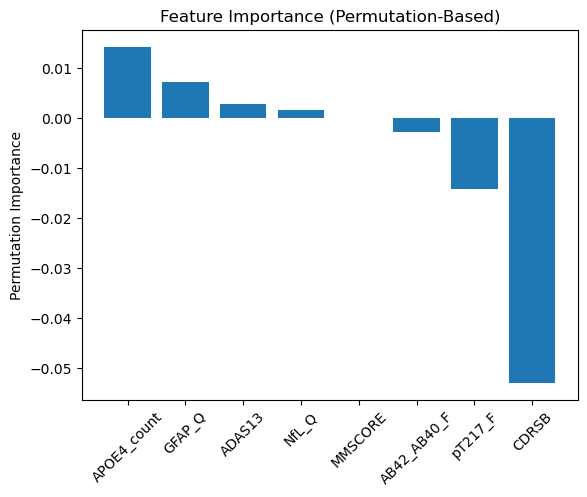

In [201]:
import matplotlib.pyplot as plt

plt.figure()
plt.bar(perm_df["Feature"], perm_df["Importance_Mean"])
plt.xticks(rotation=45)
plt.ylabel("Permutation Importance")
plt.title("Feature Importance (Permutation-Based)")
plt.show()

In [212]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.inspection import permutation_importance

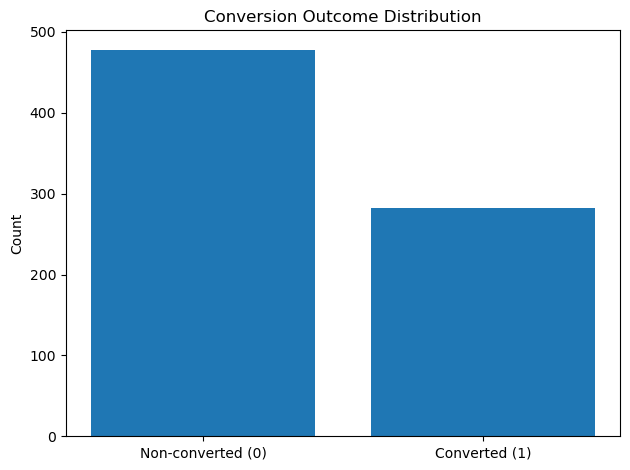

In [214]:
counts = df3["converted_to_AD"].value_counts().sort_index()

plt.figure()
plt.bar(["Non-converted (0)", "Converted (1)"], counts.values)
plt.title("Conversion Outcome Distribution")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

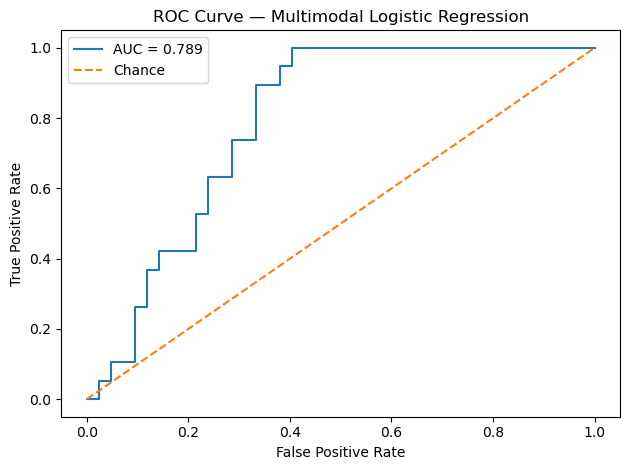

In [216]:
features = ["ADAS13","CDRSB","MMSCORE","APOE4_count","pT217_F","AB42_AB40_F","NfL_Q","GFAP_Q"]

df_model = df3.dropna(subset=features + ["converted_to_AD"]).copy()
X = df_model[features]
y = df_model["converted_to_AD"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("lr", LogisticRegression(max_iter=2000))
])

pipe.fit(X_train, y_train)
probs = pipe.predict_proba(X_test)[:, 1]

fpr, tpr, _ = roc_curve(y_test, probs)
auc = roc_auc_score(y_test, probs)

plt.figure()
plt.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--", label="Chance")
plt.title("ROC Curve — Multimodal Logistic Regression")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout()
plt.show()

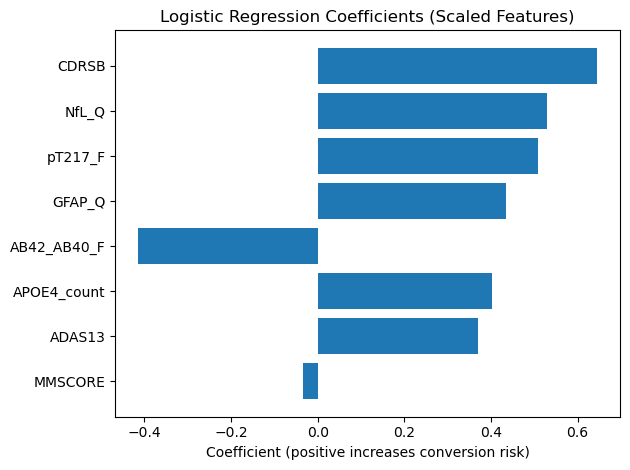

In [218]:
lr = pipe.named_steps["lr"]
coefs = lr.coef_[0]

imp = pd.DataFrame({
    "Feature": features,
    "Coefficient": coefs,
    "Abs": np.abs(coefs)
}).sort_values("Abs", ascending=True)

plt.figure()
plt.barh(imp["Feature"], imp["Coefficient"])
plt.title("Logistic Regression Coefficients (Scaled Features)")
plt.xlabel("Coefficient (positive increases conversion risk)")
plt.tight_layout()
plt.show()

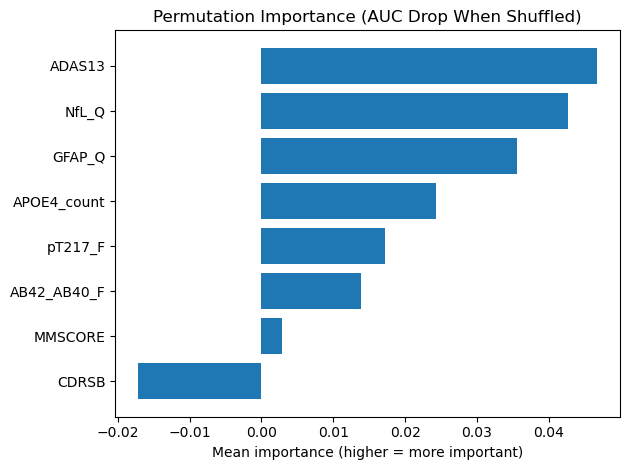

In [220]:
perm = permutation_importance(
    pipe, X_test, y_test,
    n_repeats=30, random_state=42, scoring="roc_auc"
)

perm_df = pd.DataFrame({
    "Feature": features,
    "Importance": perm.importances_mean
}).sort_values("Importance", ascending=True)

plt.figure()
plt.barh(perm_df["Feature"], perm_df["Importance"])
plt.title("Permutation Importance (AUC Drop When Shuffled)")
plt.xlabel("Mean importance (higher = more important)")
plt.tight_layout()
plt.show()

/var/folders/z1/tg0gssd15gg60mvhshzjx0lc0000gn/T/ipykernel_11633/3490537455.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([g0, g1], labels=["Non-converted", "Converted"])


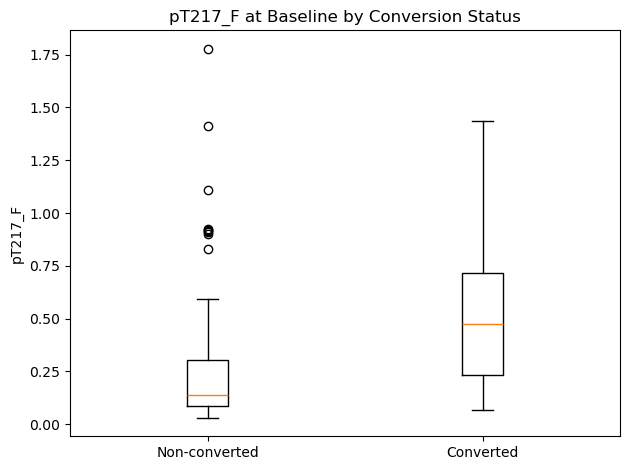

/var/folders/z1/tg0gssd15gg60mvhshzjx0lc0000gn/T/ipykernel_11633/3490537455.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([g0, g1], labels=["Non-converted", "Converted"])


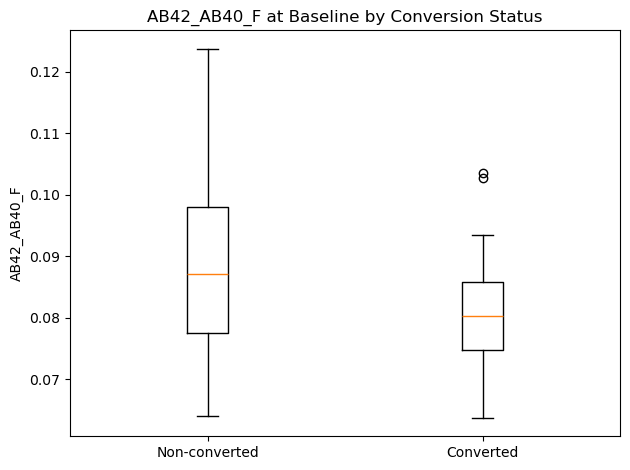

/var/folders/z1/tg0gssd15gg60mvhshzjx0lc0000gn/T/ipykernel_11633/3490537455.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([g0, g1], labels=["Non-converted", "Converted"])


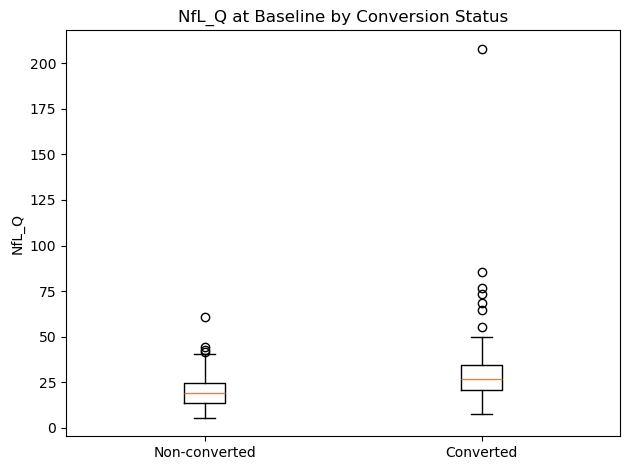

/var/folders/z1/tg0gssd15gg60mvhshzjx0lc0000gn/T/ipykernel_11633/3490537455.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([g0, g1], labels=["Non-converted", "Converted"])


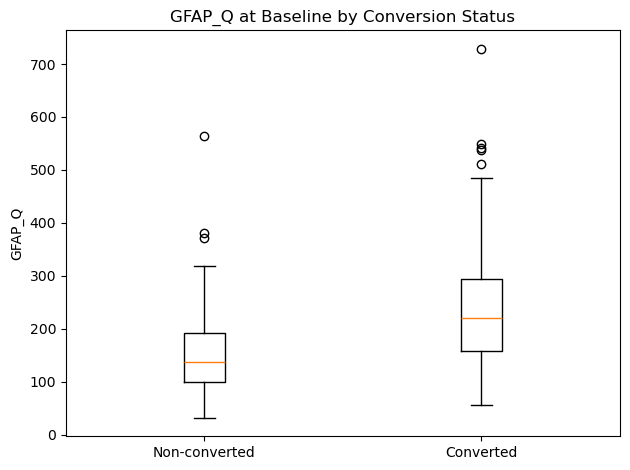

In [222]:
bio_features = ["pT217_F", "AB42_AB40_F", "NfL_Q", "GFAP_Q"]

df_bio = df3.dropna(subset=bio_features + ["converted_to_AD"]).copy()

for f in bio_features:
    g0 = df_bio[df_bio["converted_to_AD"] == 0][f].values
    g1 = df_bio[df_bio["converted_to_AD"] == 1][f].values
    
    plt.figure()
    plt.boxplot([g0, g1], labels=["Non-converted", "Converted"])
    plt.title(f"{f} at Baseline by Conversion Status")
    plt.ylabel(f)
    plt.tight_layout()
    plt.show()

/var/folders/z1/tg0gssd15gg60mvhshzjx0lc0000gn/T/ipykernel_11633/161491597.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([g0, g1], labels=["Non-converted", "Converted"])


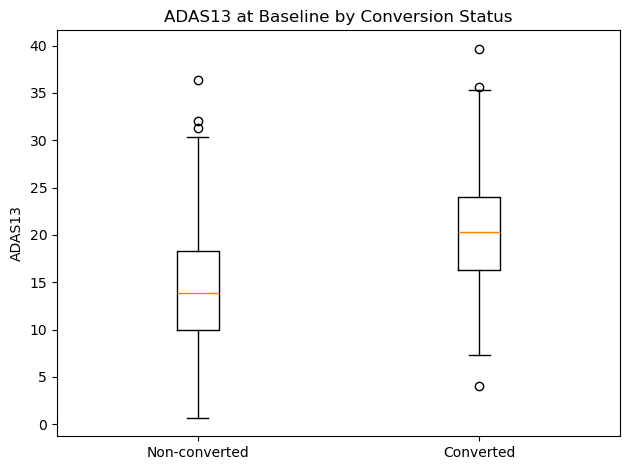

/var/folders/z1/tg0gssd15gg60mvhshzjx0lc0000gn/T/ipykernel_11633/161491597.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([g0, g1], labels=["Non-converted", "Converted"])


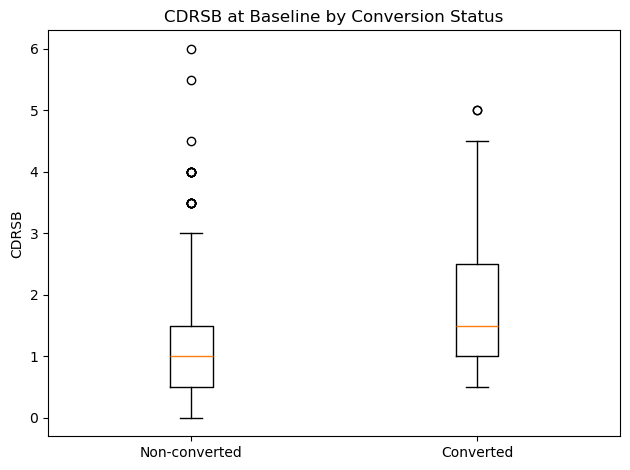

/var/folders/z1/tg0gssd15gg60mvhshzjx0lc0000gn/T/ipykernel_11633/161491597.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([g0, g1], labels=["Non-converted", "Converted"])


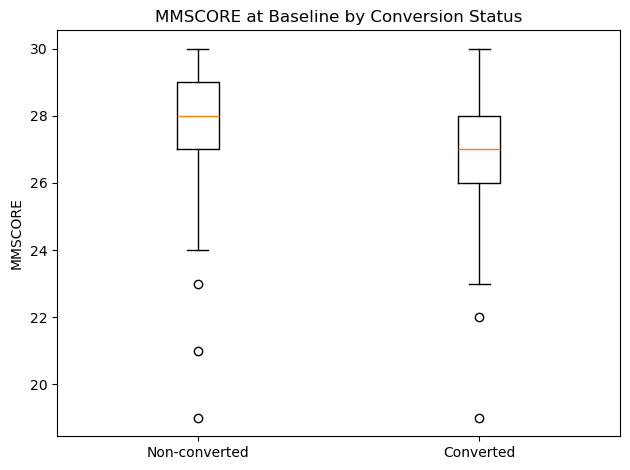

In [224]:
cog_features = ["ADAS13", "CDRSB", "MMSCORE"]

df_cog = df3.dropna(subset=cog_features + ["converted_to_AD"]).copy()

for f in cog_features:
    g0 = df_cog[df_cog["converted_to_AD"] == 0][f].values
    g1 = df_cog[df_cog["converted_to_AD"] == 1][f].values
    
    plt.figure()
    plt.boxplot([g0, g1], labels=["Non-converted", "Converted"])
    plt.title(f"{f} at Baseline by Conversion Status")
    plt.ylabel(f)
    plt.tight_layout()
    plt.show()

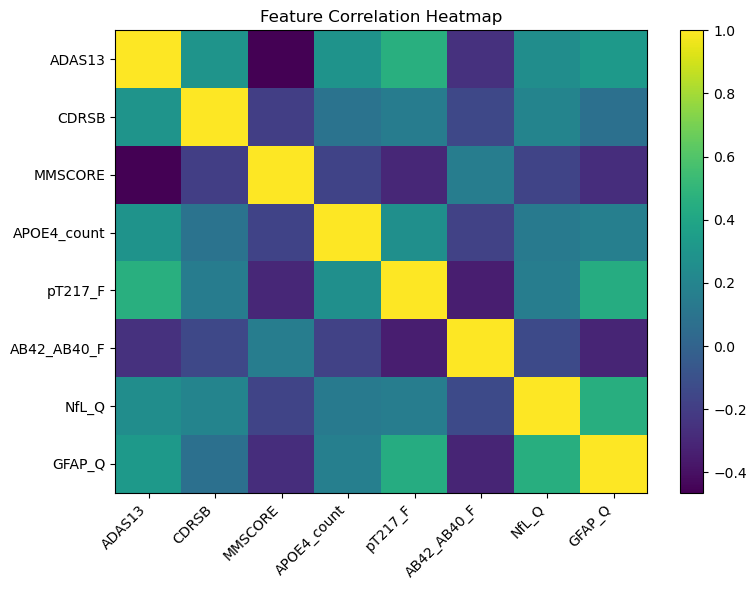

In [226]:
corr_features = ["ADAS13","CDRSB","MMSCORE","APOE4_count","pT217_F","AB42_AB40_F","NfL_Q","GFAP_Q"]
df_corr = df3[corr_features].copy()

corr = df_corr.corr(numeric_only=True)

plt.figure(figsize=(8,6))
plt.imshow(corr.values, aspect="auto")
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation=45, ha="right")
plt.yticks(range(len(corr.index)), corr.index)
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

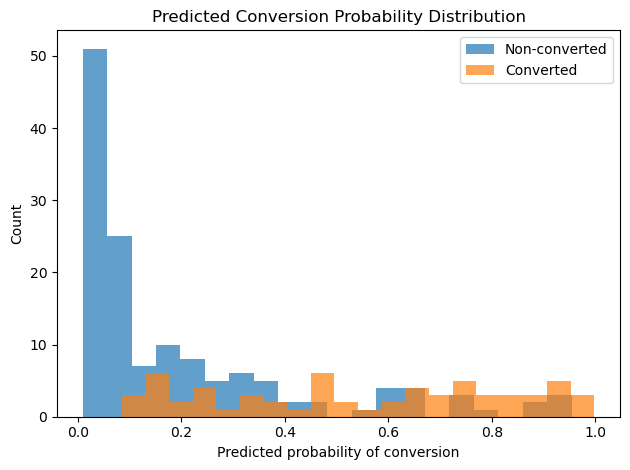

In [228]:
probs_all = pipe.predict_proba(X)[:,1]

plt.figure()
plt.hist(probs_all[y==0], bins=20, alpha=0.7, label="Non-converted")
plt.hist(probs_all[y==1], bins=20, alpha=0.7, label="Converted")
plt.title("Predicted Conversion Probability Distribution")
plt.xlabel("Predicted probability of conversion")
plt.ylabel("Count")
plt.legend()
plt.tight_layout()
plt.show()